# Entanglement of fermions with MEDT

Electrons, and the cold atoms and quasiparticles in many quantum simulators, are [fermions](https://en.wikipedia.org/wiki/Fermion). Their entanglement is different from that of qubits in two ways: swapping two fermions costs a minus sign, and nature forbids superposing states with an even and an odd number of fermions. This notebook shows what these two rules change, using three examples:

1. What makes fermions different: exchange signs and parity conservation.
2. Two-party entanglement: fermionic versus bosonic (qubit) negativity.
3. Genuine multipartite entanglement: fermionic versus bosonic GMN.

The fermionic partial transpose used throughout is that of [Shapourian, Shiozaki and Ryu (2017)](https://arxiv.org/abs/1611.07536) and [Shapourian and Ryu (2019)](https://arxiv.org/abs/1804.08637); the fermionic GMN is from [Allen, Lyu and Witczak-Krempa (2026)](https://arxiv.org/abs/2607.20707). The general introduction to the toolkit is the [tour notebook](medt_tour.ipynb).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np

import medt
from medt.fermions import (
    fermionic_keep_systems,
    fermionic_log_negativity,
    fermionic_negativity,
    fermionic_permute_systems,
    jordan_wigner_majoranas,
    random_fermionic_density_matrix,
)
from medt.states import ket_to_dm, white_noise

plt.rcParams.update({
    "figure.figsize": (6, 3.4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})
FERMION = "#2a78d6"
warnings.filterwarnings("ignore", message="Solution may be inaccurate")  # SCS accuracy notes on near-zero GMN
BOSON = "#eb6834"


## 1. What makes fermions different

### Exchange signs

Label $N$ fermionic modes (sites, orbitals) $0, \dots, N-1$ and write states in the occupation basis $|n_0 n_1 \dots\rangle$, with $n_j \in \{0, 1\}$. This looks exactly like $N$ qubits, and MEDT stores it the same way. The difference is in how states are built: $|11\rangle = c_0^\dagger c_1^\dagger |00\rangle$, and fermionic creation operators *anticommute*, $c_0^\dagger c_1^\dagger = -c_1^\dagger c_0^\dagger$. So relabelling the two modes turns $|11\rangle$ into $-|11\rangle$, while for qubits a swap leaves $|11\rangle$ unchanged.

In [2]:
psi = np.array([0, 0, 0, 1.0])  # |11>: both modes occupied
print("qubits,   swap the two systems:", psi.reshape(2, 2).T.ravel())
print("fermions, swap the two modes:  ", fermionic_permute_systems(psi, [1, 0]).real)


qubits,   swap the two systems: [0. 0. 0. 1.]
fermions, swap the two modes:   [ 0.  0.  0. -1.]


The sign is invisible in a single state, but it shows up in coherences, and therefore in reduced density matrices. Take $|\psi\rangle = (|110\rangle + |011\rangle)/\sqrt{2}$: one fermion sits on mode 1, and a second one is shared between modes 0 and 2. Ask for the reduced state of modes 2 and 0, in that order. Bringing mode 2 in front of mode 0 moves it past the occupied mode 1, so the coherence flips sign. `fermionic_keep_systems` keeps track of this; the qubit `keep_systems` does not.

In [3]:
psi = np.zeros(8)
psi[[0b110, 0b011]] = 1 / np.sqrt(2)
print("fermionic reduced state of modes (2, 0):\n", fermionic_keep_systems(psi, [2, 0]).real.round(3))
print("qubit reduced state of systems (2, 0):\n", medt.keep_systems(psi, [2, 0], [2, 2, 2]).real.round(3))


fermionic reduced state of modes (2, 0):
 [[ 0.   0.   0.  -0. ]
 [ 0.   0.5 -0.5 -0. ]
 [ 0.  -0.5  0.5 -0. ]
 [-0.  -0.  -0.   0. ]]
qubit reduced state of systems (2, 0):
 [[0.  0.  0.  0. ]
 [0.  0.5 0.5 0. ]
 [0.  0.5 0.5 0. ]
 [0.  0.  0.  0. ]]


### Majorana operators and the Jordan–Wigner string

A convenient way to write fermionic operators is through [Majorana operators](https://en.wikipedia.org/wiki/Majorana_fermion) $\gamma_{2j} = c_j + c_j^\dagger$ and $\gamma_{2j+1} = i(c_j^\dagger - c_j)$: each fermionic mode splits into two Majoranas. The [Jordan–Wigner transformation](https://en.wikipedia.org/wiki/Jordan%E2%80%93Wigner_transformation) maps them to Pauli strings, $\gamma_{2j} = Z_0 \cdots Z_{j-1} X_j$. The string of $Z$'s is what makes Majoranas on *different* modes anticommute, which no pair of single-qubit operators on different qubits can do.

In [4]:
g = jordan_wigner_majoranas(2)  # [gamma_0, gamma_1, gamma_2, gamma_3] for two modes
Z, X = np.diag([1.0, -1.0]), np.array([[0, 1], [1, 0]])
print("gamma_2 = Z (x) X:", np.allclose(g[2], np.kron(Z, X)))
print("{gamma_0, gamma_2} = 0:", np.allclose(g[0] @ g[2] + g[2] @ g[0], 0))


gamma_2 = Z (x) X: True
{gamma_0, gamma_2} = 0: True


### Parity conservation

Every physical fermionic Hamiltonian and every physical state commutes with the total fermion parity $P = (-1)^{\\sum_j n_j}$. A state like $(|0\rangle + |1\rangle)/\sqrt{2}$ on a single mode, which superposes zero and one fermion, is therefore not allowed (the *parity superselection rule*; see [Bañuls, Cirac and Wolf (2007)](https://arxiv.org/abs/0705.1103) for its role in entanglement). Physical density matrices are block diagonal in the even and odd parity sectors, as `random_fermionic_density_matrix` produces.

This rule shrinks the set of unentangled states. A single mode, on its own, can only be in a mixture of empty and occupied, with no coherence between them. So for two modes, the separable states are the mixtures of products of such diagonal states, which are diagonal in the occupation basis. Any coherence between occupation states, for example between $|01\rangle$ and $|10\rangle$ when a fermion hops between the modes, already signals fermionic entanglement.

In [5]:
rho = random_fermionic_density_matrix(3, seed=1)
parity = np.diag([(-1) ** bin(i).count("1") for i in range(8)])
print("random fermionic state commutes with parity:", np.allclose(rho @ parity, parity @ rho))


random fermionic state commutes with parity: True


## 2. Fermionic versus bosonic negativity

For qubits, the [negativity](https://arxiv.org/abs/quant-ph/0102117) comes from the partial transpose. Applying that same qubit partial transpose to a fermionic state, through Jordan–Wigner, gives the *bosonic* negativity. It ignores both rules above, and it depends on how the modes are ordered along the Jordan–Wigner string. The fermionic partial transpose of Shapourian, Shiozaki and Ryu fixes this: the *fermionic negativity* is an entanglement monotone that respects parity. Like the qubit negativity, it is computed directly from the density matrix, at a cost far below that of multipartite measures; for Gaussian (free-fermion) states it can even be obtained from two-point correlations, which reaches large systems.

**A shared Majorana pair.** Take two modes and pair up one Majorana from each, $\rho = (\mathbb{1} - i\gamma_1\gamma_2)/4$. This is the building block of the [Kitaev chain](https://en.wikipedia.org/wiki/Kitaev_chain). In the qubit picture it is the classically correlated mixture $(\mathbb{1} + X \otimes X)/4$, which has zero negativity. As a fermionic state it is entangled, with fermionic log-negativity exactly $1/2$.

In [6]:
g = jordan_wigner_majoranas(2)
rho_pair = (np.eye(4) - 1j * g[1] @ g[2]) / 4
print("equals (1 + X(x)X)/4:", np.allclose(rho_pair, (np.eye(4) + np.kron(X, X)) / 4))
print(f"bosonic negativity:       {abs(medt.negativity(rho_pair, [0], [2, 2])):.4f}")
print(f"fermionic negativity:     {fermionic_negativity(rho_pair, [0]):.4f}")
print(f"fermionic log-negativity: {fermionic_log_negativity(rho_pair, [0]):.4f}")


equals (1 + X(x)X)/4: True
bosonic negativity:       0.0000
fermionic negativity:     0.2071
fermionic log-negativity: 0.5000


**A fermion hopping between two modes, with noise.** Take one fermion in the antisymmetric superposition $(|01\rangle - |10\rangle)/\sqrt{2}$ and mix it with white noise, $\rho(p) = p\,|\psi\rangle\langle\psi| + (1-p)\,\mathbb{1}/4$. The bosonic log-negativity, $\log_2\!\left[\tfrac34(1+p) + \tfrac14|1-3p|\right]$, vanishes for $p \le 1/3$, the familiar two-qubit Werner threshold. The fermionic one, $\log_2\!\left[\tfrac12(1+p) + \tfrac12\sqrt{5p^2-2p+1}\right]$, is positive for every $p > 0$: any coherence between $|01\rangle$ and $|10\rangle$ is fermionic entanglement, as argued above.

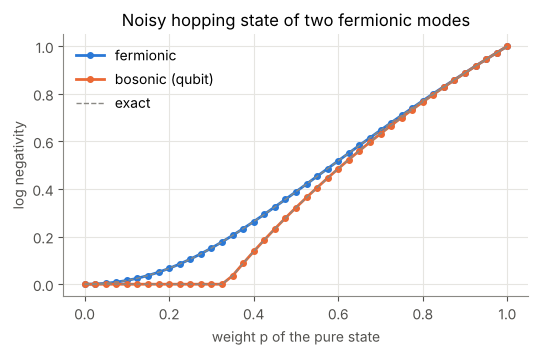

In [7]:
singlet = np.array([0, 1, -1, 0]) / np.sqrt(2)
ps = np.linspace(0, 1, 41)
bos = [medt.log_negativity(p * ket_to_dm(singlet) + (1 - p) * np.eye(4) / 4, [0], [2, 2]) for p in ps]
fer = [fermionic_log_negativity(p * ket_to_dm(singlet) + (1 - p) * np.eye(4) / 4, [0]) for p in ps]

fig, ax = plt.subplots()
ax.plot(ps, fer, color=FERMION, lw=2, marker="o", ms=4, label="fermionic")
ax.plot(ps, bos, color=BOSON, lw=2, marker="o", ms=4, label="bosonic (qubit)")
ax.plot(ps, np.log2(0.5 * (1 + ps) + 0.5 * np.sqrt(5 * ps**2 - 2 * ps + 1)), color="#8a8984", ls="--", lw=1)
ax.plot(ps, np.log2(0.75 * (1 + ps) + 0.25 * np.abs(1 - 3 * ps)), color="#8a8984", ls="--", lw=1, label="exact")
ax.set(xlabel="weight p of the pure state", ylabel="log negativity", title="Noisy hopping state of two fermionic modes")
ax.legend(frameon=False)
plt.show()


## 3. Fermionic versus bosonic GMN

The genuine multiparticle negativity (GMN) of [Jungnitsch, Moroder and Gühne (2011)](https://arxiv.org/abs/1010.6049) certifies genuine multipartite entanglement with a semidefinite program built from partial transposes across every bipartition. `medt.fermionic_gmn` replaces each one with the fermionic partial transpose, following [Allen, Lyu and Witczak-Krempa (2026)](https://arxiv.org/abs/2607.20707). Here each party is one fermionic mode.

**Three Majoranas in a loop.** Take three modes and couple one Majorana from each in a ring, $\rho = \left[\mathbb{1} - \tfrac{i}{\sqrt3}(\gamma_2\gamma_0 + \gamma_4\gamma_2 + \gamma_0\gamma_4)\right]/8$. As a qubit state it has no negativity across any cut and zero GMN, but as a fermionic state it is genuinely tripartite entangled.

In [8]:
g = jordan_wigner_majoranas(3)
rho_loop = (np.eye(8) - 1j * (g[2] @ g[0] + g[4] @ g[2] + g[0] @ g[4]) / np.sqrt(3)) / 8
print(f"bosonic GMN:   {abs(medt.gmn(rho_loop, [2, 2, 2])):.4f}")
print(f"fermionic GMN: {medt.fermionic_gmn(rho_loop):.4f}")


bosonic GMN:   0.0000


fermionic GMN: 0.1455


**Noise robustness.** Two familiar three-mode states, now read as fermions: a GHZ-like state $(|100\rangle + |010\rangle + |001\rangle + |111\rangle)/2$, with odd parity, and the W state $(|100\rangle + |010\rangle + |001\rangle)/\sqrt3$, one fermion shared among three modes. Mixing each with white noise, the fermionic GMN survives much more noise than the bosonic one: fermionic genuine multipartite entanglement persists up to $p \approx 0.80$ (GHZ-like) and $p \approx 0.73$ (W), against $4/7 \approx 0.57$ and $0.52$ for the qubit versions. Again, the parity rule makes the unentangled set smaller, so less can hide inside it.

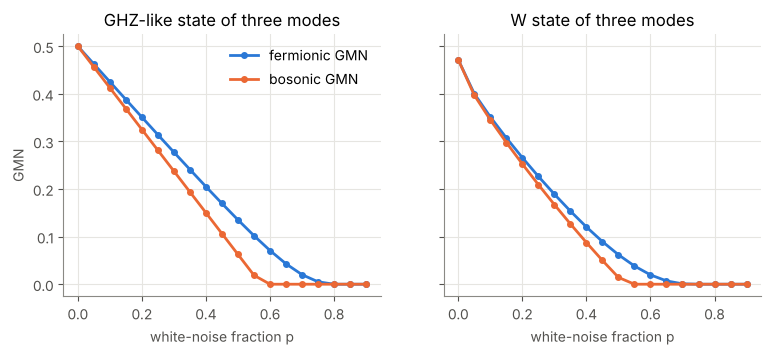

In [9]:
ghz_like = np.zeros(8)
ghz_like[[0b100, 0b010, 0b001, 0b111]] = 1 / 2
w_state = np.zeros(8)
w_state[[0b100, 0b010, 0b001]] = 1 / np.sqrt(3)
ps = np.linspace(0, 0.9, 19)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, (name, psi) in zip(axes, [("GHZ-like", ghz_like), ("W", w_state)], strict=True):
    rhos = [white_noise(ket_to_dm(psi), p) for p in ps]
    fermionic = [max(medt.fermionic_gmn(r), 0) for r in rhos]
    bosonic = [max(medt.gmn(r, [2, 2, 2]), 0) for r in rhos]
    ax.plot(ps, fermionic, color=FERMION, lw=2, marker="o", ms=4, label="fermionic GMN")
    ax.plot(ps, bosonic, color=BOSON, lw=2, marker="o", ms=4, label="bosonic GMN")
    ax.set(xlabel="white-noise fraction p", title=f"{name} state of three modes")
axes[0].set_ylabel("GMN")
axes[0].legend(frameon=False)
plt.show()


## What are we measuring?

Both fermionic measures have a concrete operational meaning, explained in [Allen, Lyu and Witczak-Krempa (2026)](https://arxiv.org/abs/2607.20707).

Because of the parity superselection rule, parties holding fermionic modes are limited to *fermionic* local operations and classical communication (fLOCC): each party may only act in ways that respect fermion parity on its own modes, and may phone the others. Fermionic entanglement is exactly what fLOCC cannot create from scratch, so it is the resource needed for tasks under these rules. Correspondingly, a fermionic biseparable state is a mixture of products $\rho_m \otimes \rho_{\bar m}$ across some bipartition $m|\bar m$ in which each factor itself respects parity.

**Two parties: reading out a Majorana phase.** Alice and Bob share $\rho(s) = (\mathbb{1} + i s\,\gamma_A \gamma_B)/4$, a Majorana pair with an unknown sign $s = \pm 1$; the state of section 2 is the case $s = -1$. Each of them, looking at their own mode, sees a maximally mixed state, and under fLOCC alone they cannot tell $s = +1$ from $s = -1$. Given a fermionically entangled resource, for instance one extra copy of $\rho(+1)$, they can identify $s$ with certainty. The fermionic negativity detects precisely this kind of resource; the qubit negativity, which is zero for these states, misses it.

**Three parties: phases that need genuine multipartite entanglement.** The paper builds three-party states whose two signs $s_1, s_2 = \pm 1$ are hidden in four-Majorana correlations spread over all three parties. Under fLOCC these signs can be decoded only with a resource that has fermionic genuine multipartite entanglement: no fermionic biseparable resource, however it is shared, will do. The fermionic GMN is an entanglement monotone under fLOCC, so a positive value certifies a resource of this kind.

In short, fermionic negativity and fermionic GMN measure entanglement as a resource for parties who must obey the rules that fermions impose, which is why they can differ so much from their qubit counterparts.

## Where to go next

- [Allen, Lyu and Witczak-Krempa (2026)](https://arxiv.org/abs/2607.20707) introduce the fermionic GMN, prove its properties and give the decoding protocols above.
- [Shapourian and Ryu (2019)](https://arxiv.org/abs/1804.08637) classify few-mode fermionic states by their negativity.
- `medt.fermions` also builds Gaussian (free-fermion) thermal states, `fermionic_gaussian_thermal_state`, for experiments with larger systems.
- The [tour notebook](medt_tour.ipynb) covers the qubit methods, and the [README](../README.md) lists every function with its references.